In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split


In [9]:
data = pd.read_csv("mnist_784_csv.csv")

In [10]:
print("Dataset Shape:", data.shape)
print(data.head())

Dataset Shape: (70000, 785)
   pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0       0       0       0       0       0       0       0       0       0   
1       0       0       0       0       0       0       0       0       0   
2       0       0       0       0       0       0       0       0       0   
3       0       0       0       0       0       0       0       0       0   
4       0       0       0       0       0       0       0       0       0   

   pixel10  ...  pixel776  pixel777  pixel778  pixel779  pixel780  pixel781  \
0        0  ...         0         0         0         0         0         0   
1        0  ...         0         0         0         0         0         0   
2        0  ...         0         0         0         0         0         0   
3        0  ...         0         0         0         0         0         0   
4        0  ...         0         0         0         0         0         0   

   pixel782  pixel783  pixel784  c

In [11]:

# Separate labels and pixel values
if data.shape[1] == 785:

    # First column contains digit labels
    labels = data.iloc[:, 0].values

    # Remaining columns contain pixel values
    X = data.iloc[:, 1:].values

else:

    # Dataset contains only pixel values
    X = data.values
    labels = None

# Convert to float
X = X.astype("float32")

# Normalize pixel values
X = X / 255.0

print("Images Shape:", X.shape)


Images Shape: (70000, 784)


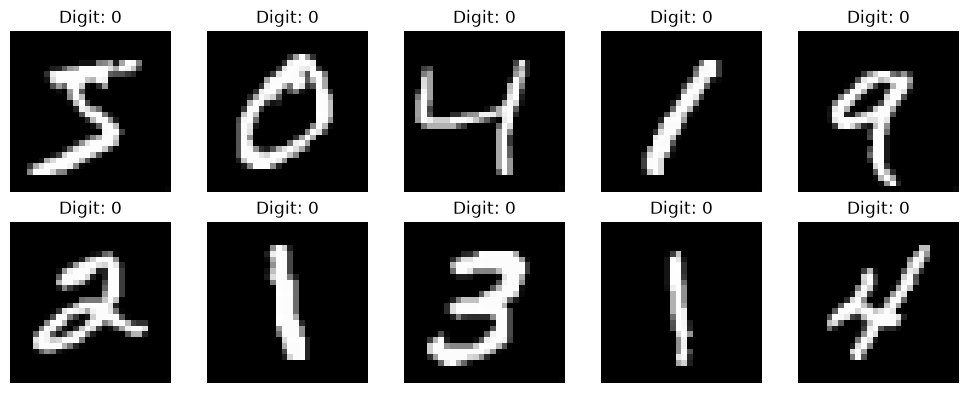

In [12]:

# Display 10 sample images
plt.figure(figsize=(10, 4))

for i in range(10):

    # Convert 784 pixels into 28 x 28 image
    image = X[i].reshape(28, 28)

    plt.subplot(2, 5, i + 1)

    plt.imshow(image, cmap="gray")

    if labels is not None:
        plt.title("Digit: " + str(labels[i]))
    else:
        plt.title("Image " + str(i + 1))

    plt.axis("off")

plt.tight_layout()
plt.show()


In [13]:

# Split dataset
x_train, x_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)


Training Data: (56000, 784)
Testing Data: (14000, 784)


In [14]:

# Input layer
input_img = keras.Input(shape=(784,))

# Encoder
encoded = layers.Dense(
    128,
    activation="relu"
)(input_img)

# Sparse encoded representation
encoded = layers.Dense(
    32,
    activation="relu",
    activity_regularizer=keras.regularizers.l1(0.001)
)(encoded)

# Decoder
decoded = layers.Dense(
    128,
    activation="relu"
)(encoded)

# Reconstructed image
output_img = layers.Dense(
    784,
    activation="sigmoid"
)(decoded)

# Create autoencoder
autoencoder = keras.Model(
    input_img,
    output_img
)

# Display model summary
autoencoder.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:

# Compile model
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)


In [16]:

# Train model
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_split=0.1
)


Epoch 1/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2935 - val_loss: 0.1984
Epoch 2/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1768 - val_loss: 0.1627
Epoch 3/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1570 - val_loss: 0.1516
Epoch 4/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1490 - val_loss: 0.1451
Epoch 5/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1435 - val_loss: 0.1406
Epoch 6/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1397 - val_loss: 0.1375
Epoch 7/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1367 - val_loss: 0.1349
Epoch 8/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1343 - val_loss: 0.1326
Epoch 9/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1321 - val_loss: 0.1308
Epoch 10/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1303 - val_loss: 0.1288


In [17]:

# Evaluate model
loss = autoencoder.evaluate(
    x_test,
    x_test,
    verbose=0
)

print("Test Reconstruction Loss:", loss)


Test Reconstruction Loss: 0.12901932001113892


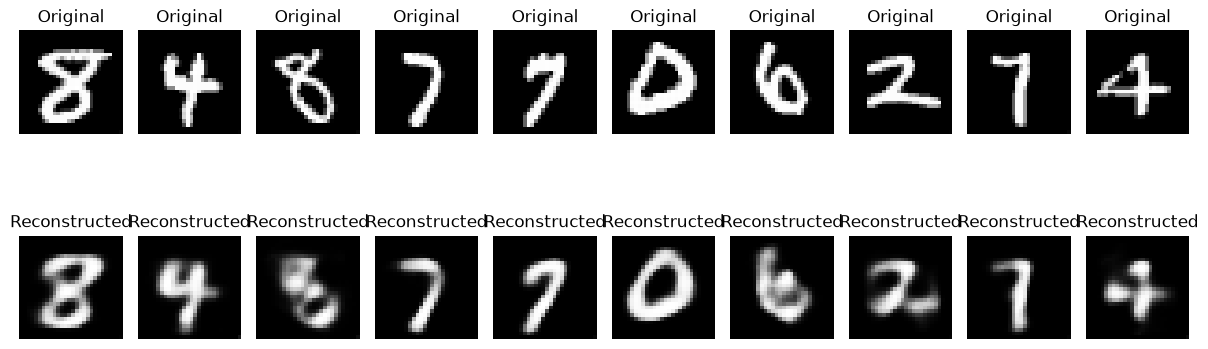

In [18]:

# Reconstruct first 10 test images
reconstructed = autoencoder.predict(
    x_test[:10],
    verbose=0
)

# Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)

    plt.imshow(
        x_test[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)

    plt.imshow(
        reconstructed[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [19]:

# Create encoder model
encoder = keras.Model(
    autoencoder.input,
    autoencoder.layers[2].output
)

# Get encoded representations
encoded_images = encoder.predict(
    x_test[:10],
    verbose=0
)

# Display encoded representation
print("Encoded Representation:")
print(encoded_images[0])

# Calculate sparsity
sparsity = np.mean(
    np.abs(encoded_images) < 0.01
)

print("Sparsity Percentage:", sparsity * 100)


Encoded Representation:
[0.2621004  0.         0.         1.0239024  0.         0.48874936
 1.4365222  0.         0.9405992  0.08192471 0.         0.
 0.26352736 0.         0.         0.7253062  0.         0.
 0.48358607 0.0534713  0.         0.         0.06510933 0.
 0.         0.         0.30951515 0.         0.4079842  0.
 0.         1.8909332 ]
Sparsity Percentage: 57.8125
